<a href="https://colab.research.google.com/github/Infinite-Sami/Sami-ppt/blob/master/%D0%9A%D1%80%D1%83%D1%82%D0%BE%D0%B9%D0%A4%D0%B0%D0%B9%D0%BB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №1. Регрессия на основе нейронных сетей

Сеимуратов Даниил Русланович
24-ИИ
Вариант 1 (Ames Housing / Предсказание цен на недвижимость)

Цель работы — построить модель глубокой нейронной сети на базе фреймворка Keras для решения задачи регрессии

  Целевая переменная: `SalePrice` — итоговая стоимость объекта недвижимости в долларах.
  
  Датасет содержит 79 объясняющих признаков (колонок), описывающих различные аспекты жилых домов в Эймсе, штат Айова (площадь, качество материалов, год постройки, количество комнат и т.д.).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

print("Размер train:", train_df.shape)
print("Размер test:", test_df.shape)

Размер train: (1460, 81)
Размер test: (1459, 80)


### Первичный анализ наборов данных
базовые команды `head`, `tail`, `info`, `describe` и `shape` для тренировочной и тестовой выборок, чтобы оценить структуру данных, типы признаков и наличие пропусков.

In [3]:
print("INFO")
display(train_df.info())
print("\nTRAIN HEAD")
display(train_df.head(3))
print("\nTAIL")
display(train_df.tail(3))
print("\nDESCRIBE")
display(train_df.describe())

print("\nSHAPE", test_df.shape)

INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  Ove

None


TRAIN HEAD


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500



TAIL


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500



DESCRIBE


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



SHAPE (1459, 80)



1.  Колонка `Id` не несет прогностической ценности, поэтому удаляется из обоих наборов.
2.
   - Для категориальных признаков (например, `Alley`, `BsmtQual`, `FireplaceQu`) пропуски означают отсутствие элемента (согласно описанию `data_description.txt`), поэтому заполняем их строкой `'None'`.
   - Для числовых признаков с небольшим количеством пропусков (например, `MasVnrArea`) заполненные медианным значением или нулем.
3.  Используем One-Hot Encoding (`pd.get_dummies`), чтобы перевести текстовые категории в числовой формат, понятный нейронной сети. Чтобы структура колонок в train и test совпадала, предварительно объединяем их или выравниваем по индексам.
4.  Признаки имеют разный масштаб (например, площадь в тысячах квадратных метров и годы). Применяем `StandardScaler` для нормализации числовых фичей к нулевому среднему и единичной дисперсии.

In [4]:
y_train = train_df['SalePrice']
train_features = train_df.drop(['Id', 'SalePrice'], axis=1)
test_features = test_df.drop(['Id'], axis=1)

ntrain = train_features.shape[0]
all_data = pd.concat([train_features, test_features]).reset_index(drop=True)

cat_cols_with_none = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
                      'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageFinish',
                      'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']
for col in cat_cols_with_none:
    all_data[col] = all_data[col].fillna('None')

for col in all_data.select_dtypes(include=['object']).columns:
    all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

for col in all_data.select_dtypes(include=['number']).columns:
    all_data[col] = all_data[col].fillna(all_data[col].median())

all_data = pd.get_dummies(all_data)

X_train = all_data.iloc[:ntrain, :]
X_test = all_data.iloc[ntrain:, :]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Размер обучающей выборки после предобработки:", X_train_scaled.shape)

Размер обучающей выборки после предобработки: (1460, 301)


### Разделение данных и архитектура нейронной сети
* Делим обучающий набор данных (`X_train_scaled`, `y_train`) в пропорции **80/20** для валидации в процессе обучения.
* Полносвязная нейронная сеть (Sequential) на базе Keras:
  - Входной слой + скрытый слой (128 нейронов, активация `relu`) + Dropout (0.2 для предотвращения переобучения).
  - Скрытый слой (64 нейрона, активация `relu`) + Dropout (0.2).
  - Выходной слой (1 нейрон) для задачи регрессии (предсказание цены).
* Оптимизатор `adam`, функция потерь `mean_squared_error` (MSE), метрика качества `mae`.

In [5]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

X_tr, X_val, y_tr, y_val = train_test_split(X_train_scaled, y_train, test_size=0.2, random_state=42)

model = Sequential([
    Dense(128, activation='relu', input_shape=(X_tr.shape[1],)),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 38883332096.0000 - mae: 181436.0781 - val_loss: 39647207424.0000 - val_mae: 178824.2188
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 38864728064.0000 - mae: 181396.0000 - val_loss: 39607619584.0000 - val_mae: 178744.7031
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 38786441216.0000 - mae: 181234.5781 - val_loss: 39464919040.0000 - val_mae: 178463.3125
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 38565679104.0000 - mae: 180774.6094 - val_loss: 39123226624.0000 - val_mae: 177782.8438
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 38103183360.0000 - mae: 179803.6562 - val_loss: 38471438336.0000 - val_mae: 176469.3125
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 37271703552.0000 - mae: 178064.2812 - val_loss: 37449056256.0000 - val_mae: 174372.0938
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 36042620928.0000 - mae: 175389.6094 - val_loss: 35910045696.0000 - val_

### Анализ результатов обучения
Строим график изменения функции потерь на обучающей и валидационной выборках по эпохам

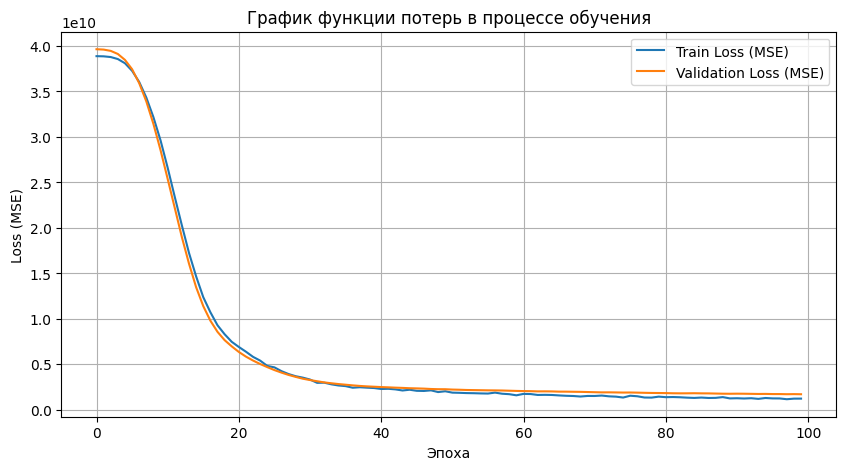

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')
plt.title('График функции потерь в процессе обучения')
plt.xlabel('Эпоха')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()

### Оценка качества модели
Считаем метрики MAE и RMSE на валидационном наборе, а также строим график остатков (`Residual Plot`), чтобы проверить наличие систематической ошибки модели.

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
MAE на валидации: 27522.05
RMSE на валидации: 41030.84


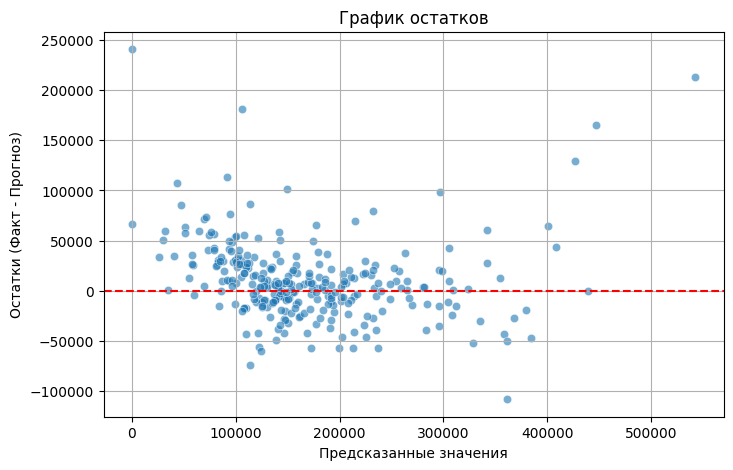

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

val_preds = model.predict(X_val).flatten()

mae = mean_absolute_error(y_val, val_preds)
rmse = np.sqrt(mean_squared_error(y_val, val_preds))

print(f"MAE на валидации: {mae:.2f}")
print(f"RMSE на валидации: {rmse:.2f}")

# Residual Plot (График остатков)
residuals = y_val - val_preds

plt.figure(figsize=(8, 5))
sns.scatterplot(x=val_preds, y=residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('График остатков')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки (Факт - Прогноз)')
plt.grid(True)
plt.show()